# STAR Project – Exploring the Data

**Research question:** Does the benefit of small classes (K–3) last over time, up to grade 8 and high school?

**Data:** Project STAR, Tennessee. Students were randomly assigned to a **small class** (13–17),
a **regular class** (22–25) or a **regular class with a teacher aide**, from kindergarten (1985) to grade 3.
Scores were then followed up to grade 8, and high school graduation was collected later.
Source: Harvard Dataverse (hdl:1902.1/10766). Variable details: `starUsersGuide.pdf`.

**This notebook:** get to know the data before any analysis.
1. Load the data
2. The key variables
3. Who is in the data, and when?
4. Were the groups similar at the start?
5. Were small classes really small?
6. Math scores
7. Complications: missing data and switching
8. Summary

## 1. Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)

df = pd.read_spss("../data/raw/STAR_Students.sav")
df = df.copy()   # makes the table faster to work with

print(df.shape)  # (rows, columns)

(11601, 379)


**11,601 students** (one row each) and **379 variables**.

## 2. The key variables

Most column names start with the grade: `gk` = kindergarten, `g1`–`g8` = grades 1–8, `hs` = high school.
Out of 379 columns, we need only a few:

| Variable | Meaning | Grades |
|---|---|---|
| `gkclasstype` … `g3classtype` | Class type: small / regular / regular + aide (**the treatment**) | K–3 only |
| `gktmathss` … `g8tmathss` | Total math score (**the outcome**) | K–8 |
| `gkclasssize` | Number of students in the class | K |
| `gender`, `race`, `gkfreelunch` | Background. Free lunch = low-income family | – |
| `gkschid` | School ID (randomization was done **inside** each school) | K |
| `hsgrdcol` | Graduated high school (YES / NO) | HS |

**Important:** K–3 math was the Stanford test (SAT). Grades 4–8 used a different test (CTBS).
Scores jump between grade 3 and 4, so we only compare groups **within** the same grade.

We also create two helper columns:
- `first_classtype` – the class type the student got when they **entered** the study
- `entry_grade` – the grade in which they entered (some joined after kindergarten)

In [2]:
grades = ["gk", "g1", "g2", "g3", "g4", "g5", "g6", "g7", "g8"]
k3 = ["gk", "g1", "g2", "g3"]
grade_labels = ["K", "1", "2", "3", "4", "5", "6", "7", "8"]

classtype_cols = [f"{g}classtype" for g in k3]
math_cols = [f"{g}tmathss" for g in grades]

df["first_classtype"] = df[classtype_cols].astype(object).bfill(axis=1).iloc[:, 0]
df["entry_grade"] = np.array(grade_labels[:4])[df[classtype_cols].notna().values.argmax(axis=1)]

df[["stdntid", "gender", "race", "gkfreelunch", "first_classtype", "entry_grade", "gktmathss", "g8tmathss", "hsgrdcol"]].head()

,stdntid,gender,race,gkfreelunch,first_classtype,entry_grade,gktmathss,g8tmathss,hsgrdcol
0,10000.0,MALE,WHITE,NaN,REGULAR + AIDE CLASS,1,NaN,NaN,NaN
1,10001.0,MALE,WHITE,NON-FREE LUNCH,REGULAR + AIDE CLASS,K,NaN,782.0,NaN
2,10002.0,FEMALE,BLACK,NaN,REGULAR + AIDE CLASS,3,NaN,645.0,NO
3,10003.0,MALE,WHITE,NaN,REGULAR CLASS,1,NaN,768.0,YES
4,10004.0,FEMALE,BLACK,NaN,REGULAR + AIDE CLASS,2,NaN,791.0,NO


## 3. Who is in the data, and when?

**a.** In which grade did students join the study, and with which class type?

In [11]:
entry = pd.crosstab(df["entry_grade"], df["first_classtype"], margins=True, margins_name="Total")
entry = entry.reindex(["K", "1", "2", "3", "Total"])            # put K first
entry["% of all students"] = (entry["Total"] / len(df) * 100).round(1)
entry["% in small class"] = (entry["SMALL CLASS"] / entry["Total"] * 100).round(1)
entry

first_classtype,REGULAR + AIDE CLASS,REGULAR CLASS,SMALL CLASS,Total,% of all students,% in small class
entry_grade,,,,,,
K,2231,2194,1900,6325,54.5,30.0
1,903,1026,385,2314,19.9,16.6
2,659,654,366,1679,14.5,21.8
3,456,454,373,1283,11.1,29.1
Total,4249,4328,3024,11601,100.0,26.1


**b.** In each year of the experiment (K–3): how many students had joined so far, how many were in the study that year,
how many were not (they left), and how many of those in the study have a math score?

In [12]:
turnover = pd.DataFrame(index=grade_labels[:4])
turnover["joined so far"] = [df["entry_grade"].isin(grade_labels[:i + 1]).sum() for i in range(4)]
turnover["in study this year"] = [df[c].notna().sum() for c in classtype_cols]
turnover["joined but not in study (left)"] = turnover["joined so far"] - turnover["in study this year"]
turnover["% of those in study with a score"] = [
    (df[ct].notna() & df[m].notna()).sum() / df[ct].notna().sum() * 100
    for ct, m in zip(classtype_cols, math_cols[:4])
]
turnover.round(1)

,joined so far,in study this year,joined but not in study (left),% of those in study with a score
K,6325,6325,0,92.8
1,8639,6829,1810,96.6
2,10318,6840,3478,88.7
3,11601,6802,4799,89.3


> 💡 **הסבר לעצמי (b):**
> - **joined so far** = כמה ילדים הצטרפו לניסוי *אי פעם* עד אותה שנה (מצטבר, רק עולה).
> - **in study this year** = כמה ילדים היו בניסוי *באותה שנה* בפועל.
> - **ההפרש** = ילדים שהצטרפו בעבר ועזבו.
>
> **כמו חוג:** 10 נרשמו, אחר כך 3 עזבו ו-4 חדשים הצטרפו.
> הצטרפו אי פעם = 14, לומדים עכשיו = 11, עזבו = 3.
>
> **אצלנו:** המספר בניסוי נשאר בערך 6,800 כל שנה, אבל הילדים מתחלפים.
> עד כיתה ג' כבר עזבו 4,799 ילדים. לכן צריך לבדוק אם מי שעזב שונה ממי שנשאר.

**c.** How many students have a math score in each grade, K to 8?

,students,% of all students
K,5871,50.6
1,6598,56.9
2,6065,52.3
3,6077,52.4
4,4331,37.3
5,2589,22.3
6,6422,55.4
7,4888,42.1
8,6213,53.6


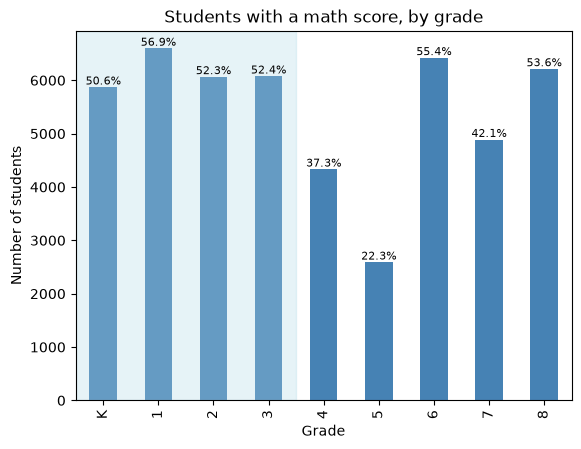

In [13]:
n_scores = pd.DataFrame(index=grade_labels)
n_scores["students"] = [df[col].notna().sum() for col in math_cols]
n_scores["% of all students"] = (n_scores["students"] / len(df) * 100).round(1)
display(n_scores)

# chart, with the % written on top of each bar
ax = n_scores["students"].plot(kind="bar", color="steelblue", title="Students with a math score, by grade")
for i, (n, p) in enumerate(zip(n_scores["students"], n_scores["% of all students"])):
    ax.text(i, n + 50, f"{p}%", ha="center", fontsize=8)
plt.axvspan(-0.5, 3.5, color="lightblue", alpha=0.3)   # experiment years
plt.xlabel("Grade")
plt.ylabel("Number of students")
plt.show()

**What we see:**
- **(a)** Only 54.5% started in K – the rest joined in grades 1–3 (kindergarten was not mandatory then).
- **(b)** About 6,800 students were in the study each year, but they kept changing: by grade 3, 4,799 had left.
  Almost everyone who was in the study that year has a score (88.7%–96.6%).
- **(c)** After the experiment, the number of scores goes up and down: grade 4 = 37.3%, **grade 5 = 22.3%**, grade 7 = 42.1%.
  Grades 4–5 have known data problems (User Guide). Grade 7 – no explanation yet.
- **(c)** Grades 6 and 8 have more students than grade 3 – students were found again through state records.

> 💡 **בעברית:**
> - **(a)** רק 54.5% התחילו בגן. השאר הצטרפו בכיתות א'–ג' (הגן לא היה חובה אז).
> - **(b)** כל שנה היו בניסוי בערך 6,800 תלמידים, אבל הם התחלפו. עד כיתה ג' עזבו 4,799.
>   כמעט כל מי שהיה בניסוי באותה שנה נבחן (88.7%–96.6%).
> - **(c)** אחרי הניסוי מספר הציונים עולה ויורד: כיתה ד' 37.3%, **כיתה ה' 22.3%**, כיתה ז' 42.1%.
>   לכיתות ד'–ה' יש בעיות נתונים ידועות (לפי המדריך). לכיתה ז' עדיין אין הסבר.
> - **(c)** בכיתות ו' וח' יש יותר תלמידים מאשר בכיתה ג', כי התלמידים אותרו שוב דרך הרשומות של המדינה.

## 4. Were the groups similar at the start?

If randomization worked, the three class types should have a similar background.
We check kindergarten students only (the original randomization).

In [4]:
k = df[df["gkclasstype"].notna()]

def pct(col, value):
    """% of students (with data) in each class type who have this value."""
    return k.groupby("gkclasstype", observed=True)[col].apply(lambda s: (s == value).sum() / s.notna().sum() * 100)

balance = pd.DataFrame({
    "% free lunch": pct("gkfreelunch", "FREE LUNCH"),
    "% white": pct("race", "WHITE"),
    "% girls": pct("gender", "FEMALE"),
    "Number of students": k.groupby("gkclasstype", observed=True).size(),
}).round(1).T
balance

gkclasstype,REGULAR + AIDE CLASS,REGULAR CLASS,SMALL CLASS
% free lunch,50.3,47.7,47.1
% white,65.8,67.2,68.1
% girls,48.3,49.0,48.6
Number of students,2231.0,2194.0,1900.0


**What we see:** the three groups are very similar: free lunch 47.1%–50.3%, white 65.8%–68.1%, girls 48.3%–49.0%.
The randomization worked, so later differences in scores are likely caused by class type, not by background.

> 💡 **בעברית:** שלוש הקבוצות כמעט זהות ברקע: ארוחה חינם 47.1%–50.3%, לבנים 65.8%–68.1%, בנות 48.3%–49.0%.
> ההגרלה עבדה, ולכן הבדלים בציונים בהמשך כנראה נובעים מגודל הכיתה ולא מהרקע.

The STAR researchers also compared the groups on gender, race and free lunch and found no bias (User Guide).

## 5. Were small classes really small?

Check that the treatment actually happened: class size by class type, in kindergarten.

Schools: 79 | Kindergarten classes: 325 

                      mean   min   max
gkclasstype                           
REGULAR + AIDE CLASS  22.8  15.0  28.0
REGULAR CLASS         22.4  16.0  27.0
SMALL CLASS           15.1  12.0  17.0


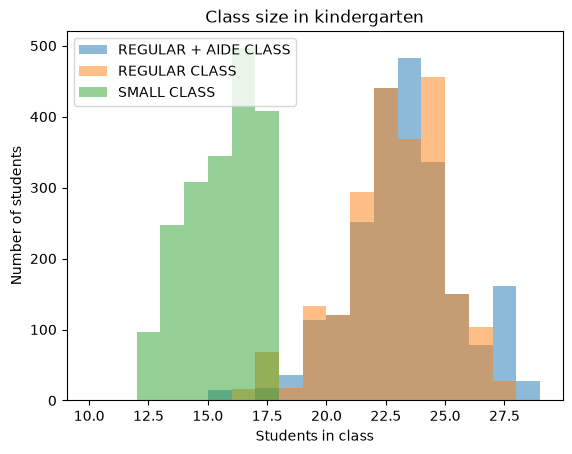

In [5]:
print("Schools:", df["gkschid"].nunique(), "| Kindergarten classes:", df["gktchid"].nunique(), "\n")
print(k.groupby("gkclasstype", observed=True)["gkclasssize"].describe()[["mean", "min", "max"]].round(1))

for ctype, group in k.groupby("gkclasstype", observed=True):
    plt.hist(group["gkclasssize"].dropna(), bins=range(10, 30), alpha=0.5, label=ctype)
plt.title("Class size in kindergarten")
plt.xlabel("Students in class")
plt.ylabel("Number of students")
plt.legend()
plt.show()

**What we see:** 79 schools and 325 kindergarten classes.
Small classes had 15.1 students on average (12–17). Regular classes had 22.4 (16–27), and regular + aide 22.8 (15–28).
The small classes are clearly separate from the regular ones, with only a small overlap around 15–17 – the treatment really happened.

Planned sizes: small 13–17, regular 22–25 (User Guide). Some regular classes became smaller because students moved out –
the User Guide calls this **"class size drift"**. This explains the small overlap around 15–17.

> 💡 **בעברית:** 79 בתי ספר ו-325 כיתות גן.
> בכיתה קטנה היו בממוצע 15.1 תלמידים (12–17), ברגילה 22.4 (16–27), וברגילה עם עוזר 22.8 (15–28).
> הכיתות הקטנות נפרדות בבירור מהרגילות, עם חפיפה קטנה סביב 15–17. הטיפול באמת קרה.
> (שימי לב: ציר Y סופר תלמידים, לא כיתות.)

## 6. Math scores

**Top:** basic statistics of the math score in each grade.
**Bottom:** average score by first class type, in each grade.

In [6]:
desc = df[math_cols].describe().T[["count", "mean", "std", "min", "max"]].round(1)
desc.index = grade_labels
desc

,count,mean,std,min,max
K,5871.0,485.4,47.7,288.0,626.0
1,6598.0,530.5,43.1,404.0,676.0
2,6065.0,580.6,44.6,441.0,721.0
3,6077.0,618.0,39.8,487.0,774.0
4,4331.0,707.0,46.5,492.0,840.0
5,2589.0,734.6,42.1,532.0,857.0
6,6422.0,751.9,44.0,553.0,874.0
7,4888.0,765.4,43.2,602.0,920.0
8,6213.0,782.3,48.8,572.0,920.0


**What we see:**
- **mean** goes up every year – students learn, so scores rise.
- Big jump between grade 3 (618.0) and grade 4 (707.0) – the test changed (SAT → CTBS), so we can't compare scores across these grades.
- **std** (spread) is similar every year, about 40–49 points.
- Grades 7 and 8 have the same max (920.0) – maybe the highest possible score on the test.

> 💡 **בעברית:** הממוצע עולה כל שנה כי התלמידים לומדים. הקפיצה בין ג' ל-ד' היא בגלל שהמבחן התחלף, לא בגלל למידה.
> הפיזור (std) דומה בכל השנים, 40–49 נקודות. בכיתות ז' וח' המקסימום זהה (920), אולי זה הציון הכי גבוה האפשרי במבחן.

first_classtype,REGULAR + AIDE CLASS,REGULAR CLASS,SMALL CLASS,gap: small − regular
K,482.8,483.2,490.9,7.7
1,528.8,526.7,538.4,11.7
2,578.0,578.8,587.0,8.2
3,615.2,616.9,623.3,6.4
4,703.9,707.2,710.6,3.4
5,731.8,733.9,739.1,5.2
6,750.7,751.1,754.7,3.6
7,763.3,764.0,770.3,6.3
8,779.8,782.2,786.0,3.8


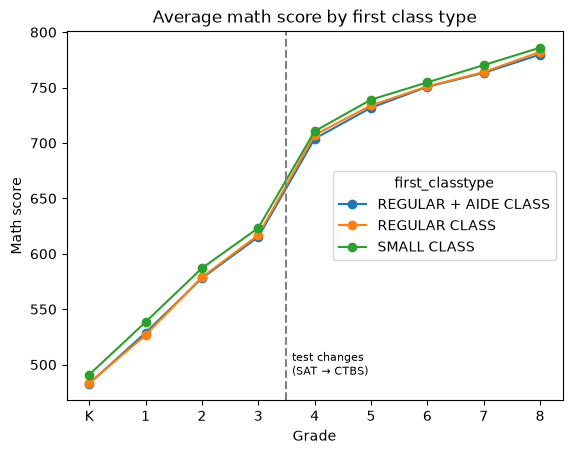

In [14]:
means = df.groupby("first_classtype")[math_cols].mean().T.round(1)
means.index = grade_labels
means["gap: small − regular"] = (means["SMALL CLASS"] - means["REGULAR CLASS"]).round(1)
display(means)

means.drop(columns="gap: small − regular").plot(marker="o", title="Average math score by first class type")
plt.axvline(3.5, color="gray", linestyle="--")
plt.text(3.6, means["SMALL CLASS"].min(), "test changes\n(SAT → CTBS)", fontsize=8)
plt.xlabel("Grade")
plt.ylabel("Math score")
plt.show()

**What we see:**
- In **every** grade, students who started in a small class have the highest average.
- The two regular class types (with and without aide) are very close to each other.
- The gap (small − regular) is biggest in grade 1 (11.7 points) and smaller later (3.8 in grade 8) – but it stays positive.
- In the chart the three lines are very close: the gap (a few points) is small compared with how much scores grow each year.
  In notebook 03 we measure it in standard deviations, with confidence intervals.

> 💡 **בעברית:** בכל שנה, לתלמידים שהתחילו בכיתה קטנה יש את הממוצע הכי גבוה. שני סוגי הכיתות הרגילות כמעט זהים.
> הפער הכי גדול בכיתה א' (11.7 נקודות), ואחר כך קטן (3.8 בכיתה ח'), אבל לא נעלם.
> בגרף הקווים קרובים מאוד, כי הפער קטן לעומת הגדילה מדי שנה. במחברת 03 נמדוד אותו בסטיות תקן.

## 7. Complications

**a. Missing data by class type**

**Why check this?** Many students have no score in later grades. If one class type loses more students than the others,
the groups are no longer comparable – differences in scores could come from *who stayed*, not from class size.

The table shows the % of students with a math score in each grade, by first class type.
(In K–2 the numbers are lower partly because some students had not joined the study yet.)

> 💡 **למה בודקים?** להרבה תלמידים אין ציון בשנים המאוחרות. אם מסוג כיתה אחד עזבו יותר תלמידים,
> הקבוצות כבר לא דומות, והבדלים בציונים יכולים לנבוע ממי *שנשאר* ולא מגודל הכיתה.

In [8]:
has_score = df.groupby("first_classtype")[math_cols].apply(lambda d: d.notna().mean() * 100).round(1)
has_score.columns = grade_labels
has_score

,K,1,2,3,4,5,6,7,8
first_classtype,,,,,,,,,
REGULAR + AIDE CLASS,48.9,56.5,52.5,52.6,36.1,21.9,55.2,41.6,53.8
REGULAR CLASS,47.0,57.1,53.0,51.9,37.4,22.0,54.8,42.8,53.5
SMALL CLASS,58.3,57.1,51.0,52.7,39.1,23.4,56.4,42.0,53.2


**What we see:**
- In grades 1–8 the three rows are very close (e.g. grade 5: 21.9%, 22.0%, 23.4%; grade 8: 53.8%, 53.5%, 53.2%).
  Dropout is similar across class types – a good sign.
- In K, small classes are higher (58.3% vs 47.0%–48.9%). This is not dropout: most small-class students started in K
  (1,900 of 3,024 in table 3a), while more regular-class students joined later.
- **But:** the same *rate* of dropout does not mean the same *kind* of students left. We check this later (loss to follow-up).

> 💡 **בעברית:** בכיתות א'–ח' שלוש השורות כמעט זהות, כלומר הנשירה דומה בכל סוגי הכיתות. זה סימן טוב.
> בגן לכיתות הקטנות יש יותר (58.3%), אבל זה לא נשירה: רוב התלמידים בכיתות הקטנות התחילו בגן, וברגילות יותר הצטרפו מאוחר.
> **אבל:** אחוז נשירה זהה לא אומר שעזבו אותם *סוגי* תלמידים. את זה נבדוק בהמשך.

**b. Switching**

**Why check this?** Students were supposed to stay in the class type they got. If many switched, the groups are mixed,
and it is less clear what we are comparing.

Rows = class type in K, columns = class type in grade 1. "Not in study" = no class type that year.
The second table shows the same thing as % of each row.

> 💡 **למה בודקים?** התלמידים היו אמורים להישאר בסוג הכיתה שהוגרל להם. אם הרבה עברו, הקבוצות מתערבבות,
> ופחות ברור מה בעצם משווים.

In [15]:
k_type = df["gkclasstype"].astype(object).fillna("Not in study")
g1_type = df["g1classtype"].astype(object).fillna("Not in study")

switch = pd.crosstab(k_type, g1_type, margins=True, margins_name="Total")
display(switch)

switch_pct = (pd.crosstab(k_type, g1_type, normalize="index") * 100).round(1)
display(switch_pct)

g1classtype,Not in study,REGULAR + AIDE CLASS,REGULAR CLASS,SMALL CLASS,Total
gkclasstype,,,,,
Not in study,2962,903,1026,385,5276
REGULAR + AIDE CLASS,642,706,761,122,2231
REGULAR CLASS,668,663,737,126,2194
SMALL CLASS,500,48,60,1292,1900
Total,4772,2320,2584,1925,11601


g1classtype,Not in study,REGULAR + AIDE CLASS,REGULAR CLASS,SMALL CLASS
gkclasstype,,,,
Not in study,56.1,17.1,19.4,7.3
REGULAR + AIDE CLASS,28.8,31.6,34.1,5.5
REGULAR CLASS,30.4,30.2,33.6,5.7
SMALL CLASS,26.3,2.5,3.2,68.0


**What we see:**
- **Small class in K:** 68.0% stayed in a small class, 26.3% left the study, and only 5.7% moved to a regular class.
- **Regular classes in K:** about 30% left (28.8%, 30.4%), and about 5.5% moved **into** a small class – this was not part of the plan.
- Many students moved between the two regular types. This **was** planned: after K, about half of the regular and
  regular + aide students were randomly re-assigned between these two types (User Guide, ch. 1).
  No student was supposed to move into or out of a small class.
- **Joined in grade 1** (row "Not in study"): only 7.3% went to a small class.

> 💡 **בעברית:**
> - מי שהתחיל בכיתה קטנה: 68% נשארו, 26.3% עזבו, ורק 5.7% עברו לכיתה רגילה.
> - מהכיתות הרגילות כ-30% עזבו, וכ-5.5% עברו **לכיתה קטנה**. זה לא היה בתוכנית.
> - הרבה עברו בין שני הסוגים הרגילים, וזה **כן** היה מתוכנן: אחרי הגן הגרילו מחדש כחצי מהתלמידים ביניהם (לפי המדריך).
> - מבין מי שהצטרף בכיתה א', רק 7.3% הלכו לכיתה קטנה.

## 8. Summary

_To do: summarize the key findings from sections 3–7._

**Open questions:**
- Why did fewer late joiners go to small classes?
- Why is grade 7 lower?
- Are the students who left different from those who stayed?